# Gothic rose window tracery

Gothic tracery is compass work: circles that touch circles. The example is a rose of eight foils, each with a trefoil
inside, above two lancets with pointed arches, all set in a pointed opening. The circles are placed by their tangency
formulas, and planex2d confirms that they touch. The stone bars are offsets of the circles, and the glass is what is
left. Lengths are in cm.

![A Gothic rose window with two lancets, stone tracery and colored glass](../_static/gallery/rose-window.png){.result}

In [1]:
import math
import matplotlib.pyplot as plt
import planex as px

## The rose

The rose has a radius `R` of 100 and `n` = 8 foils. Eight circles of radius r = R sin(π/8) / (1 + sin(π/8)) touch each
other and the rose's rim, and the center circle touches all eight. Inside each foil, three circles touch each other and
the foil.

In [2]:
R = 100.0
n = 8
r = R * math.sin(math.pi / n) / (1 + math.sin(math.pi / n))
foils = [((R - r) * math.cos(2 * math.pi * k / n + math.pi / 2), (R - r) * math.sin(2 * math.pi * k / n + math.pi / 2))
         for k in range(n)]
r3 = r * math.sin(math.pi / 3) / (1 + math.sin(math.pi / 3))
circles = [((0.0, 0.0), R), ((0.0, 0.0), R - 2 * r)] + [(c, r) for c in foils]
for k, (cx, cy) in enumerate(foils):
    a = 2 * math.pi * k / n + math.pi / 2
    for q in range(3):
        b = a + 2 * math.pi * q / 3
        circles.append(((cx + (r - r3) * math.cos(b), cy + (r - r3) * math.sin(b)), r3))


def disc(c, rho):
    return px.QuickSketch().Circle(c[0], c[1], rho).Face()

**Checks:** neighboring foils touch without overlapping, they stay inside the rim, and the center circle touches them
all:

In [3]:
rim = disc((0, 0), R)
center = disc((0, 0), R - 2 * r)
gaps = [disc(foils[k], r).Distance(disc(foils[(k + 1) % n], r)) for k in range(n)]
overlaps = [(disc(foils[k], r) * disc(foils[(k + 1) % n], r)).mass for k in range(n)]
print("foils: neighbors", max(gaps), "apart, overlapping", max(overlaps))
print("outside the rim", max((disc(c, r) - rim).mass for c in foils))
print("center circle to the foils", min(center.Distance(disc(c, r)) for c in foils), "overlapping",
      max((center * disc(c, r)).mass for c in foils))

foils: neighbors 0.0 apart, overlapping 0.0
outside the rim 0.0
center circle to the foils 0.0 overlapping 0.0


## Lancets

The two lancets have equilateral pointed arches. Each half of the arch is an arc whose center is the other springing
point, so the apex sits s √3 / 2 above them. The lancets are 60 wide with sides of 100, and a large pointed arch, 300
wide, frames the whole window. **Check:** the lancets' apexes sit s √3 / 2 above their springing, and the opening's
apex lies above the rose's top:

In [4]:
def lancet(x0, y0, s, h):
    sketch = px.QuickSketch((x0, y0)).Line((x0 + s, y0)).Line((x0 + s, y0 + h))
    sketch.Arc(center=(x0, y0 + h), sweep=60).Arc(center=(x0 + s, y0 + h), sweep=60)
    return sketch.Close().Face()


lancets = [lancet(-75.0, -270.0, 60.0, 100.0), lancet(15.0, -270.0, 60.0, 100.0)]
opening = lancet(-150.0, -290.0, 300.0, 190.0)
for l in lancets:
    (x0, y0), (x1, y1) = l.bounding_box
    print("lancet apex", y1, "springing + s √3 / 2", -170 + 60 * math.sqrt(3) / 2)
(x0, y0), (x1, y1) = opening.bounding_box
print("opening apex", round(y1, 3), "rose top", R)

lancet apex -118.03847577293368 springing + s √3 / 2 -118.03847577293368
lancet apex -118.03847577293368 springing + s √3 / 2 -118.03847577293368
opening apex 159.808 rose top 100.0


## Stone and glass

Every circle and every lancet becomes a stone bar 3 wide, the offset of its outline by 1.5. The wall surrounds the
opening, 8 wide, and the glass is what is left inside the rose and the lancets.

In [5]:
bars = [px.QuickSketch().Circle(c[0], c[1], rho).Wire().Offset(1.5) for c, rho in circles]
stone = px.Unify(bars + [l.outer.Offset(1.5) for l in lancets])
glass = px.Unify([rim, *lancets]) - stone
wall = opening.outer.Offset(8.0) + (opening - px.Unify([rim, *lancets]))
print(len(glass.faces), "panes of glass,", round(glass.mass), "cm² of glass and",
      round((stone * px.Unify([rim, *lancets])).mass), "cm² of stone tracery")

75 panes of glass, 37849 cm² of glass and 9989 cm² of stone tracery


The window, with the panes in eight colors:

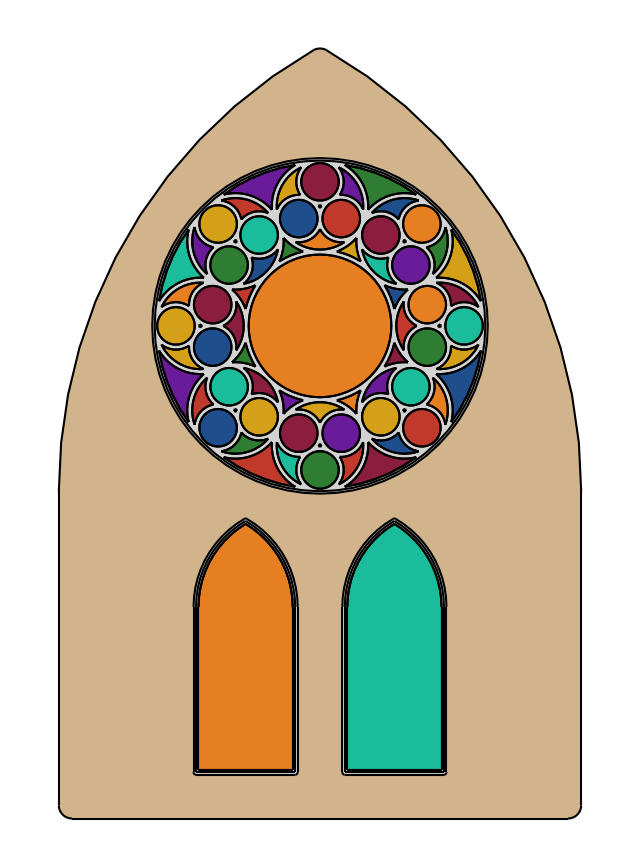

In [6]:
palette = ["#8b1e3f", "#1f4e8c", "#d4a017", "#2e7d32", "#6a1b9a", "#c0392b", "#1abc9c", "#e67e22"]
fig, ax = plt.subplots(figsize=(8, 11))
wall.Plot(ax=ax, face_col="tan", legend=False)
panes = sorted(glass.faces, key=lambda f: (round(math.atan2(f.center[1], f.center[0]), 2), f.mass))
for k, pane in enumerate(panes):
    pane.Plot(ax=ax, face_col=palette[k % len(palette)], legend=False)
stone.Plot(ax=ax, face_col="lightgray", legend=False)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

In [7]:
import sys
sys.path.insert(0, "..")
from gallery import save_scene, save_figure, save_animation, HIDDEN
save_figure(fig, "rose-window")

'/workspace/planex/documentation/docs/_static/gallery/rose-window.png'